Treatment Means:
   treatment   area_mm2
0          0  19.276547
1         50  20.662162
2        100  20.482794
3        200  17.998154
4        500  13.127852
5       1000   9.991674

Quadratic Fit Coefficients:
a (x^2 term): 0.00000585
b (x term): -0.016879
c (intercept): 20.8575
R-squared: 0.9463
Treatment Means of Plant Max Leaf Area:
   treatment   area_mm2
0          0  57.737599
1         50  57.336215
2        100  57.628688
3        200  60.360576
4        500  33.337045
5       1000  28.230676

Quadratic Fit Coefficients (for max leaf area):
a: 0.00002058
b: -0.055076
c: 61.6189
R-squared: 0.8684


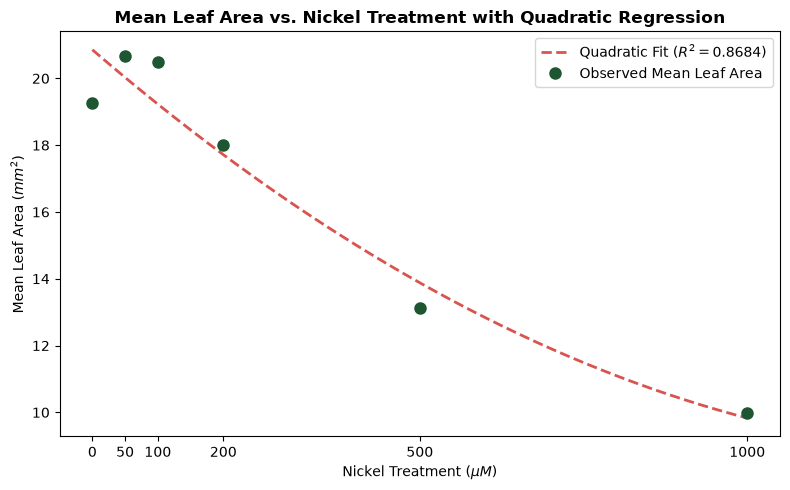

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Load design and features datasets
design = pd.read_csv("rgb2-design.csv")
features = pd.read_csv("rgb2-features.csv")

# Merge plant-level treatment (nickel level) and mean area_mm2 across plants for each treatment
merged = features.merge(
    design[["plant_id", "treatment"]].drop_duplicates(),
    on="plant_id",
    how="left",
)

# Calculate mean leaf area (mm2) for each nickel treatment level
treatment_means = (
    merged.groupby("treatment")["area_mm2"].mean().reset_index()
)
print("Treatment Means:")
print(treatment_means)

x = treatment_means["treatment"].values
y = treatment_means["area_mm2"].values

# Fit a 2nd degree polynomial (quadratic regression): y = a*x^2 + b*x + c
poly_coeffs = np.polyfit(x, y, 2)
a, b, c = poly_coeffs

print(f"\nQuadratic Fit Coefficients:")
print(f"a (x^2 term): {a:.8f}")
print(f"b (x term): {b:.6f}")
print(f"c (intercept): {c:.4f}")

# Calculate R-squared
y_pred = np.polyval(poly_coeffs, x)
ss_res = np.sum((y - y_pred) ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)
r_squared = 1 - (ss_res / ss_tot)
print(f"R-squared: {r_squared:.4f}")

# Also check plant-level means (average max leaf area per plant, or overall mean per plant first)
plant_max = features.groupby("plant_id")["area_mm2"].max().reset_index()
plant_max = plant_max.merge(
    design[["plant_id", "treatment"]].drop_duplicates(), on="plant_id", how="left"
)

treatment_max_means = (
    plant_max.groupby("treatment")["area_mm2"].mean().reset_index()
)
print("Treatment Means of Plant Max Leaf Area:")
print(treatment_max_means)

x_max = treatment_max_means["treatment"].values
y_max = treatment_max_means["area_mm2"].values

poly_coeffs_max = np.polyfit(x_max, y_max, 2)
a_max, b_max, c_max = poly_coeffs_max

print(f"\nQuadratic Fit Coefficients (for max leaf area):")
print(f"a: {a_max:.8f}")
print(f"b: {b_max:.6f}")
print(f"c: {c_max:.4f}")

y_pred_max = np.polyval(poly_coeffs_max, x_max)
r2_max = 1 - (
    np.sum((y_max - y_pred_max) ** 2) / np.sum((y_max - np.mean(y_max)) ** 2)
)
print(f"R-squared: {r2_max:.4f}")

# Generate plot and save code snippet for user
fig, ax = plt.subplots(figsize=(8, 5))

# Plot mean points from slide 16
ax.errorbar(
    x,
    y,
    fmt="o",
    color="#1e5631",
    label="Observed Mean Leaf Area",
    capsize=4,
    markersize=8,
)

# Generate smooth x line for quadratic fit curve
x_curve = np.linspace(0, 1000, 200)
y_curve = a * x_curve**2 + b * x_curve + c

# KEY UPDATED HERE: Uses r2_max (0.8684) in the legend label
ax.plot(
    x_curve,
    y_curve,
    "--",
    color="#d9534f",
    linewidth=2,
    label=f"Quadratic Fit ($R^2 = {r2_max:.4f}$)",
)

ax.set_title(
    "Mean Leaf Area vs. Nickel Treatment with Quadratic Regression",
    fontsize=12,
    fontweight="bold",
)
ax.set_xlabel("Nickel Treatment ($\mu M$)", fontsize=10)
ax.set_ylabel("Mean Leaf Area ($mm^2$)", fontsize=10)
ax.set_xticks([0, 50, 100, 200, 500, 1000])
ax.legend()
plt.tight_layout()
plt.savefig("quadratic_regression_slide16.png", dpi=300)
plt.show()

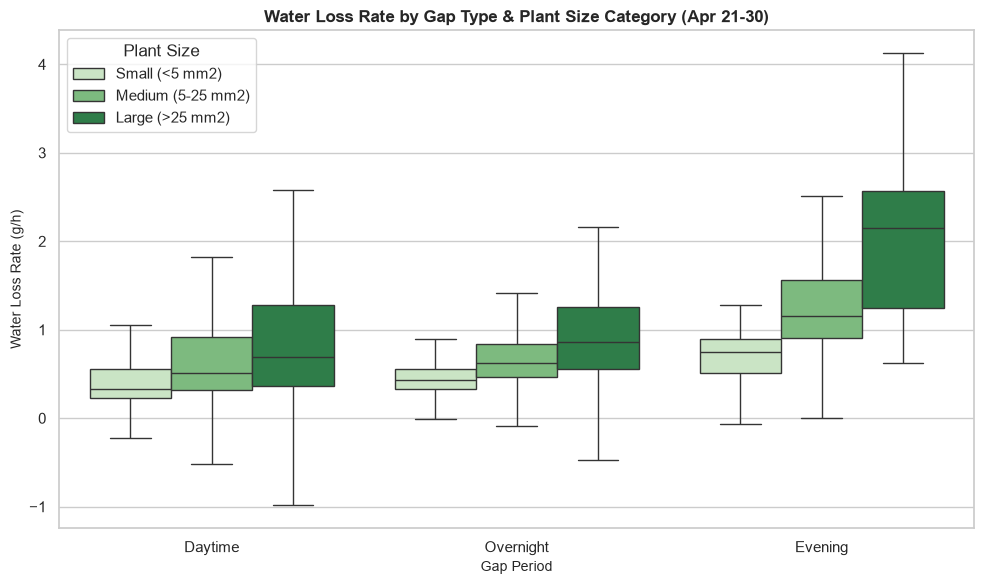

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Load Data
pw = pd.read_csv('plant-weights.csv')
design = pd.read_csv('rgb2-design.csv')
features = pd.read_csv('rgb2-features.csv')

# 2. Preprocess & Clean Window Filtering
pw['datetime'] = pd.to_datetime(pw['datetime'])
pw = pw.sort_values(by=['plant_id', 'datetime']).reset_index(drop=True)
plant_meta = design[['plant_id', 'genotype', 'treatment']].drop_duplicates()
pw = pw.merge(plant_meta, on='plant_id', how='left')

pw_clean = pw[
    (pw['datetime'] >= '2026-04-21')
    & (pw['datetime'] <= '2026-04-30 23:59:59')
].copy()
pw_clean['prev_weight_after'] = pw_clean.groupby('plant_id')[
    'weight_after_watering_g'
].shift(1)
pw_clean['prev_datetime'] = pw_clean.groupby('plant_id')['datetime'].shift(1)
pw_clean['time_gap_hours'] = (
    pw_clean['datetime'] - pw_clean['prev_datetime']
).dt.total_seconds() / 3600.0
pw_clean['water_loss_g'] = (
    pw_clean['prev_weight_after'] - pw_clean['weight_g']
)
pw_clean['water_loss_rate_g_per_h'] = (
    pw_clean['water_loss_g'] / pw_clean['time_gap_hours']
)


def get_gap_type(dt):
  hour = dt.hour
  if 6 <= hour < 17:
    return 'Daytime'
  elif 17 <= hour < 22:
    return 'Evening'
  else:
    return 'Overnight'


pw_clean['gap_type'] = pw_clean['datetime'].apply(get_gap_type)

# 3. Merge Plant Size (Leaf Area)
features['datetime'] = pd.to_datetime(features['datetime'])
features_clean = features[
    (features['datetime'] >= '2026-04-21')
    & (features['datetime'] <= '2026-04-30 23:59:59')
]
plant_area = (
    features_clean.groupby('plant_id')['area_mm2']
    .mean()
    .reset_index(name='mean_area_mm2')
)
pw_clean = pw_clean.merge(plant_area, on='plant_id', how='left')

# Categorize Plant Size
pw_clean['size_category'] = pd.cut(
    pw_clean['mean_area_mm2'],
    bins=[-np.inf, 5, 25, np.inf],
    labels=['Small (<5 mm2)', 'Medium (5-25 mm2)', 'Large (>25 mm2)'],
)

# 4. Plot Water Loss by Gap Type and Plant Size
sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=pw_clean,
    x='gap_type',
    y='water_loss_rate_g_per_h',
    hue='size_category',
    palette='Greens',
    showfliers=False,
    ax=ax,
)

ax.set_title(
    'Water Loss Rate by Gap Type & Plant Size Category (Apr 21-30)',
    fontsize=12,
    fontweight='bold',
)
ax.set_xlabel('Gap Period', fontsize=10)
ax.set_ylabel('Water Loss Rate (g/h)', fontsize=10)
plt.legend(title='Plant Size')
plt.tight_layout()
plt.savefig('water_loss_by_plant_size.png', dpi=300)
plt.show()